# BLOK · Partie 1 · SQL et analyse business (S1 2026)

DuckDB piloté depuis Python. Date de référence : 30/06/2026. Montants en FCFA. Les requêtes sont aussi dans `sql/`.

Démarche : 1) profiler les colonnes utilisées par les règles, 2) écrire chaque règle métier une seule fois dans une vue SQL, 3) vérifier par un contrôle indépendant, 4) répondre aux questions à partir des vues.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
(ROOT / "outputs").mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.0f}".replace(",", " ") if abs(x) >= 1000 else f"{x:.1f}")

con = duckdb.connect()
for t in ["organizations", "product_variants", "quotes", "quote_items", "orders", "order_items", "invoices"]:
    con.execute(f"CREATE TABLE {t} AS SELECT * FROM read_csv_auto('{(ROOT / 'data' / (t + '.csv')).as_posix()}')")

def sql(q):
    return con.sql(q).df()

## 1. Profilage : ce qui piège les règles métier

Régime fiscal : casse incohérente (A1) et valeurs vides (A2).

In [2]:
sql("""
    SELECT 'client/fournisseur' AS source, tax_regime, COUNT(*) AS nb FROM organizations GROUP BY ALL
    UNION ALL SELECT 'commande', tax_regime, COUNT(*) FROM orders GROUP BY ALL
    ORDER BY 1, 2
""")

,source,tax_regime,nb
0,client/fournisseur,RSI,2
1,client/fournisseur,rsi,34
2,client/fournisseur,tee,10
3,client/fournisseur,NaN,6
4,commande,Tee,6
5,commande,rsi,13
6,commande,tee,16
7,commande,NaN,230


Prix remisé : 0 au lieu de vide quand il n'y a pas de remise (A3).

In [3]:
sql("""
    SELECT CASE WHEN discounted_price_ht IS NULL THEN 'vide'
                WHEN discounted_price_ht = 0 THEN 'zéro' ELSE 'remise réelle' END AS cas,
           COUNT(*) AS nb_lignes
    FROM order_items GROUP BY 1
""")

,cas,nb_lignes
0,zéro,576
1,vide,40
2,remise réelle,74


Lignes facturées : sans date (A4), dans une commande supprimée (A5), facturées après le 30/06 (A6).

In [4]:
sql("""
    SELECT CASE WHEN oi.invoiced_date IS NULL THEN 'A4 sans date'
                WHEN o.is_deleted AND NOT oi.is_deleted THEN 'A5 commande supprimée, ligne active'
                WHEN oi.invoiced_date > DATE '2026-06-30' THEN 'A6 facturée après le 30/06' END AS anomalie,
           COUNT(*) AS nb_lignes,
           SUM(oi.quantity * COALESCE(NULLIF(oi.discounted_price_ht, 0), oi.price_ht)) AS montant_ht
    FROM order_items oi JOIN orders o USING (order_id)
    WHERE oi.active_status = 'invoiced'
    GROUP BY 1 HAVING anomalie IS NOT NULL ORDER BY 1
""")

,anomalie,nb_lignes,montant_ht
0,A4 sans date,7,1 273 740
1,"A5 commande supprimée, ligne active",11,10 837 830
2,A6 facturée après le 30/06,4,563 180


Valeur extrême : la plus grosse ligne de commande (A7).

In [5]:
sql("""
    SELECT oi.order_id, oi.quantity, oi.price_ht, pv.list_price_ht, oi.quantity * oi.price_ht AS montant_ht,
           o.quote_number, org.name AS client, org.tax_regime, i.total_ttc, i.amount_paid
    FROM order_items oi
    JOIN orders o USING (order_id)
    JOIN organizations org ON org.organization_id = o.client_id
    JOIN product_variants pv USING (variant_id)
    LEFT JOIN invoices i ON i.order_id = o.order_id
    ORDER BY montant_ht DESC LIMIT 3
""")

,order_id,quantity,price_ht,list_price_ht,montant_ht,quote_number,client,tax_regime,total_ttc,amount_paid
0,265,12000,5 300,5200,63 600 000,NaN,Chantier Pont Est (consortium),tee,63600000,63600000
1,122,384,37 790,36000,14 511 360,DV-2026-0235,Résidence Akwaba,rsi,17123405,0
2,189,359,37 360,36000,13 412 240,DV-2026-0370,Agro-Transformation Sud,tee,14612600,14612600


Prix de devis saisis environ 1 000 fois trop haut (A11).

In [6]:
sql("""
    SELECT q.quote_number, q.salesman, q.status, qi.quantity, qi.unit_price_ht, pv.list_price_ht,
           ROUND(qi.unit_price_ht / pv.list_price_ht) AS ratio_catalogue
    FROM quote_items qi JOIN quotes q USING (quote_id) JOIN product_variants pv USING (variant_id)
    WHERE qi.unit_price_ht > 100 * pv.list_price_ht
""")

,quote_number,salesman,status,quantity,unit_price_ht,list_price_ht,ratio_catalogue
0,DV-2026-0223,S01,accepted,3,88 780 000,95000,935.0
1,DV-2026-0427,S04,rejected,11,7 500 000,6800,1 103
2,DV-2026-0428,S02,accepted,2,15 380 000,14500,1 061


Factures : `remains` incohérent (A12), échéance vide (A14), délais de paiement accordés.

In [7]:
sql("""
    SELECT COUNT(*) FILTER (WHERE remains <> total_ttc - amount_paid)                 AS remains_incoherent,
           COUNT(*) FILTER (WHERE due_date IS NULL AND type = 'invoice')              AS sans_echeance,
           SUM(total_ttc - amount_paid) FILTER (WHERE due_date IS NULL AND type = 'invoice') AS reste_du_sans_echeance,
           MAX(DATE_DIFF('day', invoice_date, due_date))                               AS delai_paiement_max_j,
           COUNT(*) FILTER (WHERE type = 'credit_note')                                AS nb_avoirs
    FROM invoices
""")

,remains_incoherent,sans_echeance,reste_du_sans_echeance,delai_paiement_max_j,nb_avoirs
0,4,7,99 780,60,4


Ce que le profilage impose :
- A1, A2 : régime normalisé avec `LOWER`, RSI par défaut si vide (règles 3 et 4).
- A3 : 576 lignes ont 0 au lieu de vide. Un `COALESCE(discounted_price_ht, price_ht)` prendrait 0 comme prix. On utilise `COALESCE(NULLIF(discounted_price_ht, 0), price_ht)`.
- A4, A5, A6 : lignes exclues par la règle 1, en filtrant `is_deleted` au niveau commande et ligne.
- A7 : la commande 265 (12 000 sacs de ciment, 63,6 M HT) n'a pas de devis, mais elle est facturée, payée et au prix catalogue. On la garde et on montre les chiffres avec et sans elle.
- A11 : 3 prix de devis sont à environ 1 000 fois le catalogue. Divisés par 1 000, ils redeviennent cohérents : correction dans la vue des devis.
- A12, A14 : `remains` est faux sur 4 factures et 7 factures n'ont pas d'échéance. Reste dû recalculé ; échéance imputée à facture + 60 jours (délai maximal observé).

## 2. Vues de base (règles 1 à 7)

In [8]:
con.execute("""
CREATE VIEW ventes_facturees AS
WITH lignes AS (
    SELECT oi.order_item_id, oi.order_id, o.client_id, oi.variant_id, oi.quantity,
           DATE_TRUNC('month', oi.invoiced_date)                       AS mois,
           COALESCE(NULLIF(oi.discounted_price_ht, 0), oi.price_ht)    AS prix_vente,       -- règle 2
           oi.purchase_price_ht                                        AS prix_achat,
           COALESCE(LOWER(o.tax_regime), LOWER(cli.tax_regime), 'rsi') AS regime_vente,     -- règle 3
           COALESCE(LOWER(fou.tax_regime), 'rsi')                      AS regime_fournisseur -- règle 4
    FROM order_items oi
    JOIN orders o             ON o.order_id = oi.order_id
    JOIN organizations cli    ON cli.organization_id = o.client_id
    JOIN organizations fou    ON fou.organization_id = oi.supplier_id
    WHERE oi.active_status = 'invoiced'                                                    -- règle 1
      AND oi.invoiced_date BETWEEN DATE '2026-01-01' AND DATE '2026-06-30'
      AND o.status <> 'cancelled'
      AND NOT o.is_deleted AND NOT oi.is_deleted
)
SELECT *,
       quantity * prix_vente                                                     AS ca_ht,
       quantity * prix_vente * IF(regime_vente = 'tee', 1, 1.18)                 AS ca_ttc,
       quantity * prix_achat * IF(regime_fournisseur = 'rsi', 1.18, 1)           AS achats_ttc,
       quantity * prix_achat                                                     AS achats_ht,
       -- règle 5 : coût majoré de 18 % si client TEE et fournisseur RSI
       quantity * prix_achat * IF(regime_vente = 'tee' AND regime_fournisseur = 'rsi', 1.18, 1) AS cout_marge
FROM lignes
""");

In [9]:
con.execute("""
CREATE VIEW devis_retenus AS
WITH versions AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY quote_number ORDER BY version DESC) AS rang,
           COUNT(*) OVER (PARTITION BY quote_number)                           AS nb_versions,
           MIN(creation_date) OVER (PARTITION BY quote_number)                 AS date_creation_devis
    FROM quotes
),
montants AS (
    SELECT qi.quote_id, COUNT(*) AS nb_lignes,
           -- prix saisis x1000 corrigés
           SUM(qi.quantity * IF(qi.unit_price_ht > 100 * pv.list_price_ht, qi.unit_price_ht / 1000, qi.unit_price_ht)) AS montant_ht,
           ARG_MAX(pv.category, qi.quantity * pv.list_price_ht) AS categorie_principale
    FROM quote_items qi JOIN product_variants pv USING (variant_id)
    WHERE qi.is_active
    GROUP BY qi.quote_id
),
commandes AS (
    SELECT quote_number, MIN(created_at) AS date_commande
    FROM orders WHERE status <> 'cancelled' AND NOT is_deleted GROUP BY quote_number
)
SELECT v.quote_number, v.quote_id, v.client_id, v.salesman, v.status, v.nb_versions,
       v.date_creation_devis, v.creation_date AS date_derniere_version, v.sent_date,
       m.nb_lignes, m.montant_ht, m.categorie_principale,
       c.date_commande IS NOT NULL AS converti, c.date_commande
FROM versions v
JOIN montants m USING (quote_id)
LEFT JOIN commandes c USING (quote_number)
WHERE v.rang = 1 AND v.status <> 'cancelled' AND NOT v.is_deleted
""");

In [10]:
con.execute("""
CREATE VIEW creances AS
SELECT i.*, org.name AS client,
       i.total_ttc - i.amount_paid                                          AS reste_du,
       DATE_DIFF('day', COALESCE(i.due_date, i.invoice_date + 60), DATE '2026-06-30') AS jours_retard
FROM invoices i JOIN organizations org ON org.organization_id = i.client_id
WHERE i.type = 'invoice' AND NOT i.is_deleted
  AND i.invoice_date <= DATE '2026-06-30'
  AND i.total_ttc - i.amount_paid > 0
""");

Contrôle indépendant de la TVA : pour chaque facture, on recalcule le TTC à partir des lignes de commande (règles 2 et 3) et on le compare au `total_ttc` facturé.

In [11]:
sql("""
WITH ttc_lignes AS (
    SELECT oi.order_id,
           SUM(oi.quantity * COALESCE(NULLIF(oi.discounted_price_ht, 0), oi.price_ht)
               * IF(COALESCE(LOWER(o.tax_regime), LOWER(c.tax_regime), 'rsi') = 'tee', 1, 1.18)) AS ttc
    FROM order_items oi
    JOIN orders o USING (order_id)
    JOIN organizations c ON c.organization_id = o.client_id
    WHERE oi.active_status = 'invoiced' AND NOT oi.is_deleted AND oi.invoiced_date IS NOT NULL
    GROUP BY 1
)
SELECT COUNT(*) AS factures, COUNT(*) FILTER (WHERE ABS(i.total_ttc - t.ttc) <= 1) AS identiques
FROM invoices i JOIN ttc_lignes t USING (order_id)
WHERE i.type = 'invoice'
""")

,factures,identiques
0,232,232


232 factures sur 232 sont identiques au franc près. La logique de TVA est bonne, et les 7 lignes sans date (A4) ne sont sur aucune facture.

## 3. Q1 · Performance mensuelle

In [12]:
q1 = sql("""
SELECT COALESCE(STRFTIME(mois, '%Y-%m'), 'TOTAL S1')                                AS mois,
       SUM(ca_ht)                                                                   AS ca_ht,
       SUM(ca_ttc)                                                                  AS ca_ttc,
       SUM(achats_ttc)                                                              AS achats_ttc,
       SUM(ca_ht - cout_marge)                                                      AS marge_ht,
       ROUND(100 * SUM(ca_ht - cout_marge) / SUM(cout_marge), 1)                    AS marge_pct,
       SUM(ca_ht) FILTER (WHERE order_id <> 265)                                    AS ca_ht_hors_265,
       ROUND(100 * SUM(ca_ht - cout_marge) FILTER (WHERE order_id <> 265)
                 / SUM(cout_marge) FILTER (WHERE order_id <> 265), 1)               AS marge_pct_hors_265,
       ROUND(100 * SUM(ca_ht) FILTER (WHERE regime_vente = 'tee' AND regime_fournisseur = 'rsi')
                 / SUM(ca_ht), 1)                                                   AS part_ca_tee_rsi_pct
FROM ventes_facturees
GROUP BY ROLLUP (mois) ORDER BY mois NULLS LAST
""")
q1

,mois,ca_ht,ca_ttc,achats_ttc,marge_ht,marge_pct,ca_ht_hors_265,marge_pct_hors_265,part_ca_tee_rsi_pct
0,2026-01,37 298 910,42 214 498,35 576 332,5 512 421,17.3,37 298 910,17.3,12.4
1,2026-02,39 558 090,43 594 417,37 993 077,4 103 526,11.6,39 558 090,11.6,41.9
2,2026-03,24 370 890,27 406 084,23 125 839,3 154 700,14.9,24 370 890,14.9,30.7
3,2026-04,99 103 790,103 556 212,97 202 726,5 519 206,5.9,35 503 790,14.5,69.1
4,2026-05,33 581 760,38 470 704,33 293 009,4 086 200,13.9,33 581 760,13.9,16.0
5,2026-06,40 105 470,45 347 633,33 982 147,7 635 964,23.5,40 105 470,23.5,8.5
6,TOTAL S1,274 018 910,300 589 549,261 173 129,30 012 017,12.3,210 418 910,16.0,38.6


Marge selon le couple régime client / régime fournisseur, et coût de la TVA non récupérable :

In [13]:
sql("""
SELECT regime_vente || ' / ' || regime_fournisseur                         AS client_fournisseur,
       ROUND(100 * SUM(ca_ht) / (SELECT SUM(ca_ht) FROM ventes_facturees), 1) AS part_ca_pct,
       ROUND(100 * SUM(ca_ht - cout_marge) / SUM(cout_marge), 1)          AS marge_pct,
       ROUND(100 * SUM(ca_ht - achats_ht) / SUM(achats_ht), 1)            AS marge_pct_sans_tva_perdue,
       SUM(cout_marge - achats_ht)                                         AS tva_non_recuperable
FROM ventes_facturees GROUP BY 1 ORDER BY marge_pct
""")

,client_fournisseur,part_ca_pct,marge_pct,marge_pct_sans_tva_perdue,tva_non_recuperable
0,tee / rsi,38.6,2.0,20.3,15 844 833
1,rsi / rsi,41.3,18.6,18.6,0.0
2,tee / tee,7.5,21.2,21.2,0.0
3,rsi / tee,12.6,23.8,23.8,0.0


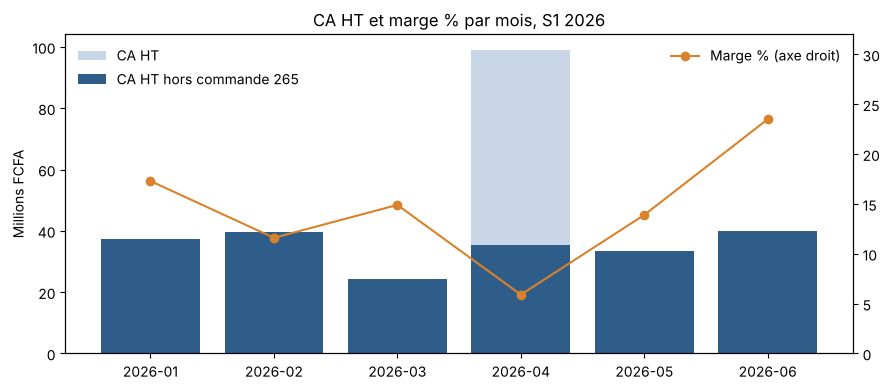

In [14]:
m = q1[q1.mois != "TOTAL S1"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(m.mois, m.ca_ht / 1e6, color="#c9d6e8", label="CA HT")
ax.bar(m.mois, m.ca_ht_hors_265 / 1e6, color="#2f5d8a", label="CA HT hors commande 265")
ax.set_ylabel("Millions FCFA")
ax2 = ax.twinx()
ax2.plot(m.mois, m.marge_pct, "o-", color="#d9822b", label="Marge % (axe droit)")
ax2.set_ylim(0, 32)
ax.legend(loc="upper left", frameon=False); ax2.legend(loc="upper right", frameon=False)
ax.set_title("CA HT et marge % par mois, S1 2026")
plt.tight_layout(); plt.savefig(ROOT / "outputs" / "q1_performance_mensuelle.png", dpi=150); plt.show()

Lecture. Le semestre totalise 274,0 M FCFA HT (300,6 M TTC) pour 30,0 M de marge (12,3 %).

- Avril sort du lot (99,1 M HT, marge 5,9 %) à cause d'une seule commande : 12 000 sacs de ciment pour Chantier Pont Est (63,6 M HT). Client exonéré (TEE), fournisseur assujetti (RSI) : BLOK paie une TVA qu'il ne peut pas refacturer et la marge de cette vente tombe à 1,6 %. Hors commande 265, avril est un mois normal (35,5 M HT, 14,5 %) et le semestre ressort à 210,4 M HT pour 16,0 % de marge.
- La vraie cause des écarts de marge est fiscale. Les ventes TEE servies par un fournisseur RSI pèsent 38,6 % du CA pour 2,0 % de marge, contre 18,6 à 23,8 % ailleurs. Sans la TVA perdue, elles feraient 20,3 %. Coût sur le semestre : 15,8 M FCFA de marge. Les mois où cette combinaison pèse lourd (février 42 %, avril 69 %) sont les mois à faible marge ; juin (8,5 %) affiche la meilleure marge (23,5 %).
- Recommandation : pour les clients TEE, acheter chez des fournisseurs TEE quand c'est possible, sinon intégrer les 18 % dans le prix dès le devis.

## 4. Q2 · Top 5 clients par CA TTC

In [15]:
sql("""
WITH par_client AS (
    SELECT client_id, SUM(ca_ttc) AS ca_ttc, SUM(ca_ht - cout_marge) AS marge_ht
    FROM ventes_facturees GROUP BY client_id
)
SELECT org.name AS client, org.segment, p.ca_ttc,
       ROUND(100 * p.ca_ttc / SUM(p.ca_ttc) OVER (), 1)     AS part_ca_ttc_pct,
       ROUND(100 * p.marge_ht / SUM(p.marge_ht) OVER (), 1) AS part_marge_pct
FROM par_client p JOIN organizations org ON org.organization_id = p.client_id
ORDER BY p.ca_ttc DESC LIMIT 5
""")

,client,segment,ca_ttc,part_ca_ttc_pct,part_marge_pct
0,Chantier Pont Est (consortium),Grand compte,75 946 675,25.3,2.7
1,Résidence Akwaba,Grand compte,28 759 777,9.6,16.2
2,Hôtel Ivoire Business,Grand compte,28 399 991,9.4,12.0
3,Promoteur Immobilier Bassam,PME,18 591 136,6.2,9.0
4,Groupe Kanga BTP,Grand compte,13 921 959,4.6,7.3


In [16]:
sql("""
WITH par_client AS (
    SELECT client_id, SUM(ca_ttc) AS ca_ttc FROM ventes_facturees WHERE order_id <> 265 GROUP BY client_id
), rangs AS (
    SELECT ca_ttc, ROW_NUMBER() OVER (ORDER BY ca_ttc DESC) AS rang FROM par_client
)
SELECT ROUND(100 * SUM(ca_ttc) FILTER (WHERE rang = 1) / SUM(ca_ttc), 1)  AS top1_pct,
       ROUND(100 * SUM(ca_ttc) FILTER (WHERE rang <= 5) / SUM(ca_ttc), 1) AS top5_pct,
       COUNT(*) AS clients_actifs
FROM rangs
""")

,top1_pct,top5_pct,clients_actifs
0,12.1,43.0,39


Lecture. Le top 5 pèse 55,1 % du CA TTC, mais la moitié vient d'une seule commande ponctuelle : hors commande 265, le premier client pèse 12,1 % et le top 5 43,0 % sur 39 clients actifs.

- Le vrai risque est sur la marge. Chantier Pont Est fait 25 % du CA mais 2,7 % de la marge. Résidence Akwaba et Hôtel Ivoire Business portent à eux deux 28 % de la marge avec 19 % du CA : ce sont eux à fidéliser en priorité.
- C'est aussi un risque de crédit : Akwaba et Promoteur Immobilier Bassam concentrent l'essentiel de l'échu (Q4).
- Le CA TTC gonfle de 18 % les clients assujettis : pour piloter la concentration, suivre le CA HT et la marge.

## 5. Q3 · Devis et commerciaux

Définitions (règle 6). Un devis = un `quote_number`, sa dernière version, ses lignes actives, hors annulés et supprimés. Il est « créé au semestre » si sa première version date du semestre (certaines versions ont des dates incohérentes, A9). Il est converti s'il existe une commande valide avec son `quote_number`. Toutes les conversions arrivent au plus 12 jours après l'envoi : un devis envoyé après le 15 juin peut encore se convertir, d'où la colonne « issue connue ».

In [17]:
sql("""
WITH s1 AS (
    SELECT *, NOT converti AND (sent_date IS NULL OR sent_date > DATE '2026-06-15') AS encore_ouvert
    FROM devis_retenus
    WHERE date_creation_devis BETWEEN DATE '2026-01-01' AND DATE '2026-06-30'
)
SELECT COALESCE(salesman, 'TOTAL')                                                 AS commercial,
       COUNT(*)                                                                     AS nb_devis,
       SUM(montant_ht)                                                              AS montant_ht,
       ROUND(100 * AVG(converti::INT), 1)                                           AS conversion_pct,
       ROUND(100 * SUM(montant_ht) FILTER (WHERE converti) / SUM(montant_ht), 1)     AS conversion_valeur_pct,
       SUM(encore_ouvert::INT)                                                      AS encore_ouverts,
       ROUND(100 * AVG(converti::INT) FILTER (WHERE NOT encore_ouvert), 1)           AS conversion_issue_connue_pct
FROM s1 GROUP BY ROLLUP (salesman) ORDER BY salesman NULLS LAST
""")

,commercial,nb_devis,montant_ht,conversion_pct,conversion_valeur_pct,encore_ouverts,conversion_issue_connue_pct
0,S01,67,126 297 360,53.7,38.7,7.0,60.0
1,S02,81,126 131 740,50.6,52.2,7.0,55.4
2,S03,72,108 203 460,43.1,23.5,4.0,45.6
3,S04,91,82 206 600,54.9,43.7,14.0,64.9
4,TOTAL,311,442 839 160,50.8,39.8,32.0,56.6


In [18]:
sql("""
SELECT salesman                                                                        AS commercial,
       ROUND(AVG(DATE_DIFF('day', date_derniere_version, sent_date)), 1)               AS delai_envoi_moyen_j,
       COUNT(*) FILTER (WHERE status = 'sent' AND NOT converti AND sent_date <= DATE '2026-06-15') AS sans_reponse,
       SUM(montant_ht) FILTER (WHERE status = 'sent' AND NOT converti AND sent_date <= DATE '2026-06-15') AS montant_sans_reponse,
       COUNT(*) FILTER (WHERE montant_ht > 5e6)                                        AS devis_plus_5M,
       COUNT(*) FILTER (WHERE montant_ht > 5e6 AND converti)                           AS convertis_plus_5M,
       COUNT(*) FILTER (WHERE sent_date IS NULL OR sent_date > DATE '2026-06-30')      AS non_envoyes_30_06,
       SUM(montant_ht) FILTER (WHERE sent_date IS NULL OR sent_date > DATE '2026-06-30') AS montant_non_envoye
FROM devis_retenus
WHERE date_creation_devis BETWEEN DATE '2026-01-01' AND DATE '2026-06-30'
GROUP BY 1 ORDER BY 1
""")

,commercial,delai_envoi_moyen_j,sans_reponse,montant_sans_reponse,devis_plus_5M,convertis_plus_5M,non_envoyes_30_06,montant_non_envoye
0,S01,2.5,10,20 121 180,8,1,5,13 290 050
1,S02,2.3,17,16 319 930,5,4,6,15 006 250
2,S03,2.6,20,59 020 250,5,0,2,109 400
3,S04,2.6,17,14 760 540,3,1,7,9 883 720


In [19]:
sql("""
SELECT CASE WHEN delai <= 3 THEN '0-3 j' WHEN delai <= 5 THEN '4-5 j' WHEN delai <= 7 THEN '6-7 j' ELSE '8 j et +' END AS delai_envoi,
       COUNT(*) AS nb_devis, ROUND(100 * AVG(converti::INT), 1) AS conversion_pct
FROM (SELECT *, DATE_DIFF('day', date_derniere_version, sent_date) AS delai FROM devis_retenus)
WHERE date_creation_devis BETWEEN DATE '2026-01-01' AND DATE '2026-06-30'
  AND sent_date <= DATE '2026-06-15'
GROUP BY 1 ORDER BY 1
""")

,delai_envoi,nb_devis,conversion_pct
0,0-3 j,202,61.9
1,4-5 j,32,53.1
2,6-7 j,21,33.3
3,8 j et +,16,6.3


Commercial à aider en priorité : S03. Il est dernier sur les trois mesures : en nombre (43,1 %), en valeur (23,5 %) et sur les devis à issue connue (45,6 %).
- Ce n'est pas un problème de réactivité : il envoie ses devis en 2,6 jours en moyenne, comme les autres.
- C'est un problème de suivi : 20 devis envoyés depuis plus de 15 jours sont restés sans réponse, pour 59,0 M HT, plus que les trois autres réunis (51,2 M). Et il ne convertit aucun de ses 5 devis de plus de 5 M (S02 en convertit 4 sur 5).
- Action : revue hebdomadaire de ses devis de plus de 2 M envoyés depuis plus de 7 jours, et binôme avec S02 sur les gros comptes.

Pour toute l'équipe : un devis envoyé en 0 à 3 jours se convertit à 62 %, à 6-7 jours à 33 %, au-delà de 8 jours à 6 %. Et 20 devis créés au semestre n'étaient pas envoyés au 30 juin (38,3 M HT), surtout chez S02 et S01.

Sans la correction A11, S04 aurait affiché 164,6 M de devis au lieu de 82,2 M.

## 6. Q4 · Créances au 30 juin 2026

In [20]:
sql("""
SELECT COALESCE(tranche, 'TOTAL') AS tranche, COUNT(*) AS nb_factures, SUM(reste_du) AS montant_ttc
FROM (SELECT *, CASE WHEN jours_retard <= 0 THEN '0. à échoir' WHEN jours_retard <= 30 THEN '1. 1-30 j'
                     WHEN jours_retard <= 60 THEN '2. 31-60 j' WHEN jours_retard <= 90 THEN '3. 61-90 j'
                     ELSE '4. 90+ j' END AS tranche FROM creances)
GROUP BY ROLLUP (tranche) ORDER BY tranche NULLS LAST
""")

,tranche,nb_factures,montant_ttc
0,0. à échoir,20,16 281 803
1,1. 1-30 j,11,27 476 796
2,2. 31-60 j,5,1 838 010
3,3. 61-90 j,1,2 039 530
4,4. 90+ j,8,637 206
5,TOTAL,45,48 273 345


Ce qu'on aurait obtenu en lisant `remains` et `overdue` tels quels (A12, A13) :

In [21]:
sql("""
    SELECT SUM(reste_du) AS encours, SUM(remains) AS encours_selon_remains,
           SUM(reste_du) FILTER (WHERE jours_retard > 0) AS echu,
           SUM(reste_du) FILTER (WHERE overdue) AS echu_selon_overdue,
           COUNT(*) FILTER (WHERE jours_retard > 0) AS nb_echues, COUNT(*) FILTER (WHERE overdue) AS nb_flag_overdue
    FROM creances
""")

,encours,encours_selon_remains,echu,echu_selon_overdue,nb_echues,nb_flag_overdue
0,48 273 345,48 064 748,31 991 542,282 793,25,3


In [22]:
sql("""
SELECT c.client,
       SUM(c.reste_du) FILTER (WHERE c.jours_retard > 0)  AS echu_ttc,
       MAX(c.jours_retard)                                AS retard_max_j,
       COALESCE(SUM(a.total_ttc), 0)                      AS avoir_non_impute
FROM creances c
LEFT JOIN invoices a ON a.order_id = c.order_id AND a.type = 'credit_note'
GROUP BY c.client
HAVING echu_ttc > 0
ORDER BY echu_ttc DESC
""")

,client,echu_ttc,retard_max_j,avoir_non_impute
0,Résidence Akwaba,17 123 405,22,0.0
1,Promoteur Immobilier Bassam,9 114 486,58,-810 367
2,Société Minière Nord,2 502 280,65,0.0
3,Chantier Pont Est (consortium),526 320,16,0.0
4,Clinique Les Palmiers,426 712,10,0.0
5,Agence Voyages Soleil,365 100,20,0.0
6,Atelier Mécanique Koumassi,364 089,50,0.0
7,Supermarché Marcory,321 821,128,0.0
8,Lycée Technique Abobo,306 199,183,0.0
9,Mairie annexe Treichville,155 949,97,0.0


Lecture. L'encours au 30 juin est de 48,3 M TTC, dont 32,0 M échus (25 factures). Si on lisait `overdue`, on verrait 0,3 M d'échu : le champ n'est positionné que sur 3 factures sur 25. `remains` sous-estime aussi l'encours de 0,2 M.

Qui relancer en premier : trois clients font 90 % de l'échu (28,7 M sur 32,0 M).
1. Résidence Akwaba : 17,1 M, en retard de 22 jours. C'est le client le plus rentable : relance par le commercial ou la direction.
2. Promoteur Immobilier Bassam : 9,1 M, jusqu'à 58 jours. Un avoir de 0,8 M n'est pas imputé : réclamer le montant net pour éviter un litige.
3. Société Minière Nord : 2,5 M, dont 2,0 M à 65 jours.

Ensuite, une relance formelle groupée des petites créances de plus de 90 jours avant qu'elles deviennent irrécouvrables (Lycée Technique Abobo, Fondation Santé Pour Tous, Supermarché Marcory, Restaurant Le Baobab, ONG Terre Verte, Mairie annexe Treichville : 0,6 M au total).

## 7. Q5 · Qualité des données

Impact chiffré des anomalies les plus lourdes, en comparant le traitement retenu au traitement naïf :

In [23]:
sql("""
    SELECT
      (SELECT SUM(oi.quantity * oi.price_ht) FROM ventes_facturees v JOIN order_items oi USING (order_item_id)
        WHERE oi.discounted_price_ht = 0)                                                  AS a3_ca_perdu_si_coalesce_naif,
      (SELECT SUM(ca_ht * 0.18) FROM ventes_facturees v JOIN orders o USING (order_id)
        WHERE o.tax_regime = 'Tee')                                                        AS a1_tva_en_trop_si_casse_ignoree,
      (SELECT SUM(qi.quantity * qi.unit_price_ht * 0.999) FROM quote_items qi JOIN product_variants pv USING (variant_id)
        JOIN devis_retenus d USING (quote_id)
        WHERE qi.is_active AND qi.unit_price_ht > 100 * pv.list_price_ht
          AND d.date_creation_devis >= DATE '2026-01-01')                                  AS a11_devis_s1_en_trop,
      (SELECT SUM(reste_du) FROM creances WHERE jours_retard > 0 AND NOT overdue)          AS a13_echu_invisible
""")

,a3_ca_perdu_si_coalesce_naif,a1_tva_en_trop_si_casse_ignoree,a11_devis_s1_en_trop,a13_echu_invisible
0,236 609 640,357 089,82 417 500,31 708 749


Contrôles automatiques : chaque requête compte les lignes en violation. En production, ils tourneraient après chaque réplication et bloqueraient la publication des indicateurs.

In [24]:
CONTROLES = {
    "A1  régime hors {rsi, tee}":              "SELECT COUNT(*) FROM (SELECT tax_regime FROM organizations UNION ALL SELECT tax_regime FROM orders) WHERE tax_regime NOT IN ('rsi', 'tee')",
    "A2  organisation sans régime":            "SELECT COUNT(*) FROM organizations WHERE tax_regime IS NULL",
    "A3  prix remisé = 0":                     "SELECT COUNT(*) FROM order_items WHERE discounted_price_ht = 0",
    "A4  ligne facturée sans date":            "SELECT COUNT(*) FROM order_items WHERE active_status = 'invoiced' AND invoiced_date IS NULL",
    "A5  ligne active, commande supprimée":    "SELECT COUNT(*) FROM order_items oi JOIN orders o USING (order_id) WHERE o.is_deleted AND NOT oi.is_deleted",
    "A6  facturation après le 30/06":          "SELECT COUNT(*) FROM order_items WHERE invoiced_date > DATE '2026-06-30'",
    "A8  dernière version de devis supprimée": "SELECT COUNT(*) FROM (SELECT * FROM quotes QUALIFY ROW_NUMBER() OVER (PARTITION BY quote_number ORDER BY version DESC) = 1) WHERE is_deleted",
    "A9  version créée avant la précédente":   "SELECT COUNT(*) FROM quotes a JOIN quotes b ON b.quote_number = a.quote_number AND b.version = a.version + 1 WHERE b.creation_date < a.creation_date",
    "A10 devis accepté sans commande valide":  "SELECT COUNT(*) FROM devis_retenus WHERE status = 'accepted' AND NOT converti",
    "A11 prix de devis > 100x catalogue":      "SELECT COUNT(*) FROM quote_items JOIN product_variants USING (variant_id) WHERE unit_price_ht > 100 * list_price_ht",
    "A12 remains <> total - payé":             "SELECT COUNT(*) FROM invoices WHERE remains <> total_ttc - amount_paid",
    "A13 overdue incohérent":                  "SELECT COUNT(*) FROM invoices WHERE type = 'invoice' AND overdue <> (due_date < DATE '2026-06-30' AND total_ttc > amount_paid)",
    "A14 facture sans échéance":               "SELECT COUNT(*) FROM invoices WHERE type = 'invoice' AND due_date IS NULL",
    "A17 client créé après son 1er devis":     "SELECT COUNT(*) FROM organizations o WHERE created_at > (SELECT MIN(creation_date) FROM quotes q WHERE q.client_id = o.organization_id)",
    "A19 devis envoyé après le 30/06":         "SELECT COUNT(*) FROM quotes WHERE sent_date > DATE '2026-06-30'",
}
controles = pd.DataFrame([(k, con.sql(q).fetchone()[0]) for k, q in CONTROLES.items()], columns=["controle", "violations"])
(ROOT / "sql" / "q5_controles_qualite.sql").write_text(
    "".join(f"-- {k}\n{q};\n\n" for k, q in CONTROLES.items()), encoding="utf-8")
controles

,controle,violations
0,"A1 régime hors {rsi, tee}",8
1,A2 organisation sans régime,6
2,A3 prix remisé = 0,576
3,A4 ligne facturée sans date,7
4,"A5 ligne active, commande supprimée",17
5,A6 facturation après le 30/06,4
6,A8 dernière version de devis supprimée,3
7,A9 version créée avant la précédente,10
8,A10 devis accepté sans commande valide,13
9,A11 prix de devis > 100x catalogue,3


| # | Anomalie | Impact | Traitement |
|---|---|---|---|
| A1 | Casse du régime (`RSI`, `Tee`) | 357 089 de TVA en trop si `Tee` n'est pas reconnu | `LOWER` |
| A2 | Régime vide (1 client, 5 fournisseurs) | Calcul fondé sur une valeur par défaut | RSI par défaut, à faire compléter |
| A3 | Prix remisé à 0 au lieu de vide | 236,6 M de CA HT perdus (86 %) | `NULLIF(…, 0)` |
| A4 | Ligne facturée sans date | 1,3 M HT, absente des factures | Exclue |
| A5 | Ligne active dans une commande supprimée | 10,8 M HT | Filtre aux deux niveaux |
| A6 | Facturation après le 30/06 | 0,6 M HT | Filtre de période |
| A7 | Commande de 12 000 sacs | 63,6 M HT, 23 % du CA | Gardée, montrée à part |
| A8 | Dernière version de devis supprimée | 3 devis | Devis exclus |
| A9 | Version créée avant la précédente | 10 cas | Devis daté par sa 1re version |
| A10 | Devis `accepted` sans commande valide | 13 devis | Cible = commande, pas statut |
| A11 | Prix de devis x1000 | 82,4 M de devis en trop (S04 doublé) | Division par 1 000 |
| A12 | `remains` faux | Encours sous-évalué de 0,2 M | Recalcul |
| A13 | `overdue` faux | 31,7 M d'échu invisibles | Recalcul depuis `due_date` |
| A14 | Échéance vide | 7 factures, 99 780 encore dus | Facture + 60 jours |
| A16 | Avoir non imputé sur facture ouverte | 0,8 M réclamés en trop | Montant net dans la relance |
| A17 | Client créé après son premier devis | 9 clients | Date de création non utilisée |
| A19 | Devis envoyé après le 30/06 | 5 devis : les statuts datent de l'extraction | Traités comme non envoyés au 30/06 |

Les trois qui comptent : A3, A11 et A13 ne provoquent aucune erreur SQL, mais donnent des chiffres faux et crédibles. C'est pour ça que chaque contrôle ci-dessus est écrit pour tourner automatiquement.

## Hypothèses

| # | Hypothèse | Justification |
|---|---|---|
| H1 | Régime normalisé en minuscules, RSI si vide | Règles 3 et 4 (A1, A2) |
| H2 | Prix remisé à 0 = pas de remise | 576 lignes à 100 % de remise n'auraient pas de sens (A3) |
| H3 | Ligne facturée sans date exclue | Règle 1 ; absente des factures (A4) |
| H4 | Marge % = marge HT / coût d'achat HT retenu (majoré dans le cas TEE + RSI) | Cohérent avec la règle 5 |
| H5 | Commande 265 conservée | Facturée, payée, au prix catalogue (A7) |
| H6 | Avoirs non déduits du CA | Le CA est défini par les lignes de commande ; effet maximal 0,9 M TTC |
| H7 | Devis daté par sa première version ; devis dont la dernière version est supprimée = supprimé | A8, A9 |
| H8 | Prix de devis > 100 fois le catalogue divisés par 1 000 | A11 |
| H9 | Reste dû et retard recalculés ; échéance manquante = facture + 60 jours | A12 à A14 |
| H10 | `amount_paid` et les statuts reflètent la date d'extraction, pas le 30/06 | Aucun historique daté (A19) |